# One-Class SVM

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

In [2]:
# Generate ring-shaped normal data plus outliers
np.random.seed(42)

# 300 normal points on two concentric circles (non-linear shape)
X_rings, _ = make_circles(n_samples=300, factor=0.5, noise=0.08, random_state=42)

# 20 outliers: center of ring + far outside points
X_center = np.random.normal(loc=0.0, scale=0.15, size=(10, 2))
X_far = np.random.uniform(low=-2.5, high=2.5, size=(10, 2))
# Keep only far points really outside the rings
X_far = X_far[np.abs(X_far).max(axis=1) > 1.5][:10]

# Combine into one dataset
X_all = np.vstack([X_rings, X_center, X_far])

# Build DataFrame
df = pd.DataFrame(X_all, columns=["feature1", "feature2"])
print(df.shape)
print(df.head())

(318, 2)
   feature1  feature2
0 -0.205549  0.441302
1  0.291795 -0.487135
2  0.385734  0.039077
3  0.852735  0.446299
4 -0.468830 -0.175415


In [3]:
# Scale features and train One-Class SVM
# Scaling is mandatory because RBF kernel is distance-based
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["feature1", "feature2"]])

# Train One-Class SVM: nu = expected outlier ratio
model = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
labels = model.fit_predict(X_scaled)

# In sklearn: 1 = inlier, -1 = outlier
df["ocsvm_label"] = labels
df["is_outlier"] = df["ocsvm_label"] == -1

# Decision function: positive = inside boundary, negative = outside
df["decision"] = model.decision_function(X_scaled)

print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df.sort_values("decision").head(10))

Detected outliers: 16
     feature1  feature2  ocsvm_label  is_outlier  decision
314  2.328160  1.541987           -1        True -1.164601
315 -0.976931 -2.011639           -1        True -0.868325
311  0.462073 -2.267748           -1        True -0.436854
316 -1.889809 -0.024115           -1        True -0.405306
313 -2.174742  2.244428           -1        True -0.268725
317 -2.328057  2.046602           -1        True -0.265449
30   0.866070  0.719722           -1        True -0.030287
174 -0.810541 -0.772668           -1        True -0.005419
189  0.106269  1.080820           -1        True -0.000508
254  0.764772 -0.789706           -1        True -0.000375


C:\Users\Lighthouse\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


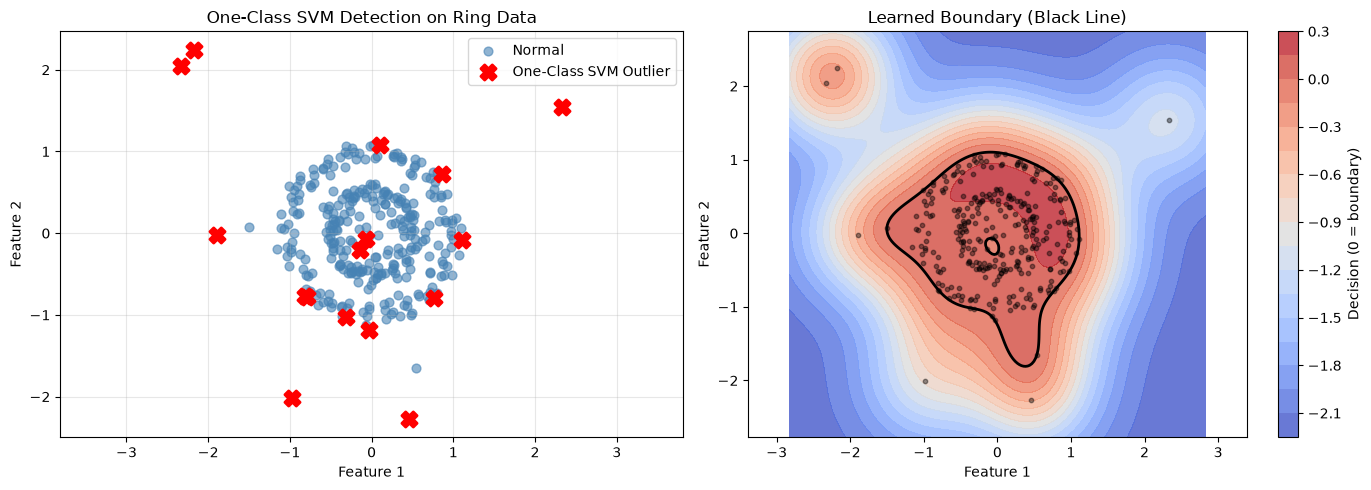

In [4]:
# Visualize boundary and decision scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: normal points vs detected outliers
normal = df[~df["is_outlier"]]
outliers = df[df["is_outlier"]]
axes[0].scatter(normal["feature1"], normal["feature2"], color="steelblue", alpha=0.6, s=40, label="Normal")
axes[0].scatter(outliers["feature1"], outliers["feature2"], color="red", marker="X", s=120, linewidths=2, label="One-Class SVM Outlier", zorder=5)
axes[0].set_title("One-Class SVM Detection on Ring Data")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].axis("equal")

# Right plot: decision function heatmap (boundary = 0)
xx, yy = np.meshgrid(np.linspace(df["feature1"].min()-0.5, df["feature1"].max()+0.5, 200),
                     np.linspace(df["feature2"].min()-0.5, df["feature2"].max()+0.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
Z = model.decision_function(grid_scaled).reshape(xx.shape)

contour = axes[1].contourf(xx, yy, Z, levels=20, cmap="coolwarm", alpha=0.8)
plt.colorbar(contour, ax=axes[1], label="Decision (0 = boundary)")
axes[1].contour(xx, yy, Z, levels=[0], colors="black", linewidths=2)
axes[1].scatter(df["feature1"], df["feature2"], color="black", s=10, alpha=0.4)
axes[1].set_title("Learned Boundary (Black Line)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].axis("equal")

plt.tight_layout()
plt.show()

In [5]:
#  Experiment - try different nu and gamma values
for nu_val in [0.02, 0.05, 0.15]:
    temp = OneClassSVM(kernel="rbf", gamma="scale", nu=nu_val)
    temp_labels = temp.fit_predict(X_scaled)
    print(f"nu={nu_val}: {(temp_labels == -1).sum()} outliers")

for g in ["scale", 0.1, 5.0]:
    temp = OneClassSVM(kernel="rbf", gamma=g, nu=0.05)
    temp_labels = temp.fit_predict(X_scaled)
    print(f"gamma={g}: {(temp_labels == -1).sum()} outliers")

# Question: What happens to the boundary when gamma=5.0 vs gamma=0.1?
# Hint: Re-run Cell 4 with each gamma and watch the black boundary line.

nu=0.02: 11 outliers
nu=0.05: 16 outliers
nu=0.15: 46 outliers
gamma=scale: 16 outliers
gamma=0.1: 13 outliers
gamma=5.0: 52 outliers
